In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter   # vai para a célula 0

In [19]:
def encontrar_raiz(marcador: str = "requirements.txt") -> Path:
    """Sobe a partir do diretório atual até achar a pasta que contém o marcador."""
    atual = Path.cwd().resolve()  # resolve() troca links simbólicos e '..' pelo caminho real

    # [atual, *atual.parents] = o próprio diretório + todos os de cima (pai, avô, ... até /)
    # Incluir 'atual' cobre o caso em que o notebook é executado da própria raiz.
    for pasta in [atual, *atual.parents]:
        if (pasta / marcador).exists():
            return pasta

    # Falha logo e com uma mensagem clara, em vez de deixar o erro estourar
    # mais adiante, num caminho do dataset que não existe.
    raise FileNotFoundError(
        f"'{marcador}' não foi encontrado a partir de {atual}. "
        "Execute o notebook de dentro do projeto TC1."
    )

In [20]:
# Raiz do projeto: o nbconvert executa o notebook com o diretório de trabalho em notebooks/
ROOT = encontrar_raiz()
RAW = ROOT / "dataset" / "raw" / "LLCP2015.XPT"
PARQUET = ROOT / "dataset" / "interim" / "llcp2015_raw.parquet"

In [ ]:
import sys
sys.path.append(str(ROOT))          # deixa o Python enxergar a pasta src/
from src.config import features

In [21]:
pd.set_option("display.max_columns", None)

In [22]:
if not PARQUET.exists():       # converte só se ainda não existir
    df = pd.read_sas(RAW, format="xport", encoding="latin-1")
    df.to_parquet(PARQUET)
df = pd.read_parquet(PARQUET)  # sempre lê do Parquet: o mesmo caminho na 1ª e na 2ª execução

In [23]:
resumo = pd.DataFrame({
    "dtype": df.dtypes,
    "pct_nulos": df.isnull().mean() * 100,      # % de vazios por coluna
    "n_unicos": df.nunique(),       # quantos valores distintos
}).round(2)


In [24]:
resumo.sort_values("pct_nulos")

,dtype,pct_nulos,n_unicos
_STATE,float64,0.00,53
FMONTH,float64,0.00,12
IDATE,str,0.00,415
IMONTH,str,0.00,12
IDAY,str,0.00,31
...,...,...,...
COLGHOUS,float64,99.99,1
QLMENTL2,float64,100.00,0
QLSTRES2,float64,100.00,0
QLHLTH2,float64,100.00,0


In [25]:
df["DIABETE3"].value_counts(dropna=False)

DIABETE3
3.0    372104
1.0     57256
4.0      7690
2.0      3608
7.0       598
9.0       193
NaN         7
Name: count, dtype: int64

In [26]:
resumo

,dtype,pct_nulos,n_unicos
_STATE,float64,0.00,53
FMONTH,float64,0.00,12
IDATE,str,0.00,415
IMONTH,str,0.00,12
IDAY,str,0.00,31
...,...,...,...
_RFSEAT2,float64,0.00,3
_RFSEAT3,float64,0.00,3
_FLSHOT6,float64,64.22,3
_PNEUMO2,float64,64.22,3


In [27]:
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,ASTHNOW,CHCSCNCR,CHCOCNCR,CHCCOPD1,HAVARTH3,ADDEPEV2,CHCKIDNY,DIABETE3,DIABAGE2,SEX,MARITAL,EDUCA,RENTHOM1,NUMHHOL2,NUMPHON2,CPDEMO1,VETERAN3,EMPLOY1,CHILDREN,INCOME2,INTERNET,WEIGHT2,HEIGHT3,PREGNANT,QLACTLM2,USEEQUIP,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,SMOKE100,SMOKDAY2,STOPSMK2,LASTSMK2,USENOW3,ALCDAY5,AVEDRNK2,DRNK3GE5,MAXDRNKS,FRUITJU1,FRUIT1,FVBEANS,FVGREEN,FVORANG,VEGETAB1,EXERANY2,EXRACT11,EXEROFT1,EXERHMM1,EXRACT21,EXEROFT2,EXERHMM2,STRENGTH,LMTJOIN3,ARTHDIS2,ARTHSOCL,JOINPAIN,SEATBELT,FLUSHOT6,FLSHTMY2,IMFVPLAC,PNEUVAC3,HIVTST6,HIVTSTD3,WHRTST10,PDIABTST,PREDIAB1,INSULIN,BLDSUGAR,FEETCHK2,DOCTDIAB,CHKHEMO3,FEETCHK,EYEEXAM,DIABEYE,DIABEDU,PAINACT2,QLMENTL2,QLSTRES2,QLHLTH2,CAREGIV1,CRGVREL1,CRGVLNG1,CRGVHRS1,CRGVPRB1,CRGVPERS,CRGVHOUS,CRGVMST2,CRGVEXPT,VIDFCLT2,VIREDIF3,VIPRFVS2,VINOCRE2,VIEYEXM2,VIINSUR2,VICTRCT4,VIGLUMA2,VIMACDG2,CIMEMLOS,CDHOUSE,CDASSIST,CDHELP,CDSOCIAL,CDDISCUS,WTCHSALT,LONGWTCH,DRADVISE,ASTHMAGE,ASATTACK,ASERVIST,ASDRVIST,ASRCHKUP,ASACTLIM,ASYMPTOM,ASNOSLEP,ASTHMED3,ASINHALR,HAREHAB1,STREHAB1,CVDASPRN,ASPUNSAF,RLIVPAIN,RDUCHART,RDUCSTRK,ARTTODAY,ARTHWGT,ARTHEXER,ARTHEDU,TETANUS,HPVADVC2,HPVADSHT,SHINGLE2,HADMAM,HOWLONG,HADPAP2,LASTPAP2,HPVTEST,HPLSTTST,HADHYST2,PROFEXAM,LENGEXAM,BLDSTOOL,LSTBLDS3,HADSIGM3,HADSGCO1,LASTSIG3,PCPSAAD2,PCPSADI1,PCPSARE1,PSATEST1,PSATIME,PCPSARS1,PCPSADE1,PCDMDECN,SCNTMNY1,SCNTMEL1,SCNTPAID,SCNTWRK1,SCNTLPAD,SCNTLWK1,SXORIENT,TRNSGNDR,RCSGENDR,RCSRLTN2,CASTHDX2,CASTHNO2,EMTSUPRT,LSATISFY,ADPLEASR,ADDOWN,ADSLEEP,ADENERGY,ADEAT1,ADFAIL,ADTHINK,ADMOVE,MISTMNT,ADANXEV,QSTVER,QSTLANG,EXACTOT1,EXACTOT2,MSCODE,_STSTR,_STRWT,_RAWRAKE,_WT2RAKE,_CHISPNC,_CRACE1,_CPRACE,_CLLCPWT,_DUALUSE,_DUALCOR,_LLCPWT,_RFHLTH,_HCVU651,_RFHYPE5,_CHOLCHK,_RFCHOL,_MICHD,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR1,_PRACE1,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACE_G1,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,_BMI5CAT,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG,_SMOKER3,_RFSMOK3,DRNKANY5,DROCDY3_,_RFBING5,_DRNKWEK,_RFDRHV5,FTJUDA1_,FRUTDA1_,BEANDAY_,GRENDAY_,ORNGDAY_,VEGEDA1_,_MISFRTN,_MISVEGN,_FRTRESP,_VEGRESP,_FRUTSUM,_VEGESUM,_FRTLT1,_VEGLT1,_FRT16,_VEG23,_FRUITEX,_VEGETEX,_TOTINDA,METVL11_,METVL21_,MAXVO2_,FC60_,ACTIN11_,ACTIN21_,PADUR1_,PADUR2_,PAFREQ1_,PAFREQ2_,_MINAC11,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,1.0,1.0,01292015,01,29,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,15.0,18.0,10.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,3.0,NaN,2.0,1.0,4.0,1.0,2.0,NaN,1.0,2.0,8.0,88.0,3.0,2.0,280.0,510.0,NaN,1.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,3.0,NaN,2.0,3.0,888.0,NaN,NaN,NaN,305.0,310.0,320.0,310.0,305.0,101.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,888.0,1.0,1.0,1.0,6.0,1.0,1.0,112014.0,1.0,1.0,1.0,NaN,NaN,1.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,1.0,,,3.0,11011.0,28.78156,3.0,86.344681,NaN,NaN,NaN,NaN,1.0,0.614125,341.384853,2.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,9.0,1.0,63.0,5.0,70.0,178.0,12701.0,4018.0,4.0,2.0,1.0,2.0,2.0,3.0,1.0,2.0,5.39

In [28]:
def prevalencia_por_idade(df, coluna, validos, rotulos):
    """Prevalência do alvo por faixa etária e pelos grupos de `coluna`.

    validos: códigos da coluna que entram (ex.: [1, 2])
    rotulos: nomes dos grupos, NA ORDEM dos códigos (ex.: ["Sim", "Não"])
    """
    d = df[["DIABETE3", "_AGEG5YR", coluna]].copy()
    d = d[d["DIABETE3"].isin([1, 2, 3, 4])]
    d["alvo"] = d["DIABETE3"].isin([1, 2, 4]).astype(int)
    d = d[d[coluna].isin(validos)]
    d["_AGEG5YR"] = d["_AGEG5YR"].replace(14, np.nan)
    d = d.dropna(subset=["_AGEG5YR"])

    tab = d.groupby(["_AGEG5YR", coluna])["alvo"].mean().unstack()
    tab.columns = rotulos
    return tab

In [29]:
def plot_prevalencia_por_idade(tab, rotulos):
    """Plota a prevalência do alvo por faixa etária e pelos grupos de `coluna`.

    tab: tabela de prevalência (output da função `prevalencia_por_idade`)
    rotulos: nomes dos grupos, NA ORDEM dos códigos (ex.: ["Sim", "Não"])
    """
    tab.columns = rotulos
    ax = tab.plot(kind="bar", figsize=(10, 6))
    FAIXAS = ["18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54",
          "55–59", "60–64", "65–69", "70–74", "75–79", "80+"]   # códigos 1 a 13 do _AGEG5YR
    ax.set_xticks(range(1, 14))                          # um tick por código...
    ax.set_xticklabels(FAIXAS, rotation=0)
    ax.set_ylabel("Prevalência do alvo")
    ax.set_xlabel("Faixa etária")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.legend(title="Grupo")
    plt.title("Prevalência do alvo por faixa etária e grupo")
    plt.xticks(rotation=0)
    plt.show()

In [30]:
expl = df[["DIABETE3", "_RFDRHV5", "_AGEG5YR"]].copy()
expl = expl[expl["DIABETE3"].isin([1, 2, 3, 4])]
expl["alvo"] = expl["DIABETE3"].isin([1, 2, 4]).astype(int)
expl = expl[expl["_RFDRHV5"].isin([1, 2])]

expl.groupby("_RFDRHV5")["alvo"].agg(["mean", "count"])


,mean,count
_RFDRHV5,,
1.0,0.161537,393019
2.0,0.074034,22044


In [31]:
expl["_AGEG5YR"] = expl["_AGEG5YR"].replace(14, np.nan)
expl = expl.dropna(subset=["_AGEG5YR"])

expl.groupby(["_AGEG5YR", "_RFDRHV5"])["alvo"].mean().unstack()

_RFDRHV5,1.0,2.0
_AGEG5YR,,
1.0,0.017788,0.018710
2.0,0.033898,0.021892
3.0,0.049783,0.034169
4.0,0.073113,0.046613
5.0,0.090984,0.057622
6.0,0.115927,0.065611
7.0,0.143816,0.078374
8.0,0.167436,0.077610
9.0,0.206007,0.093124


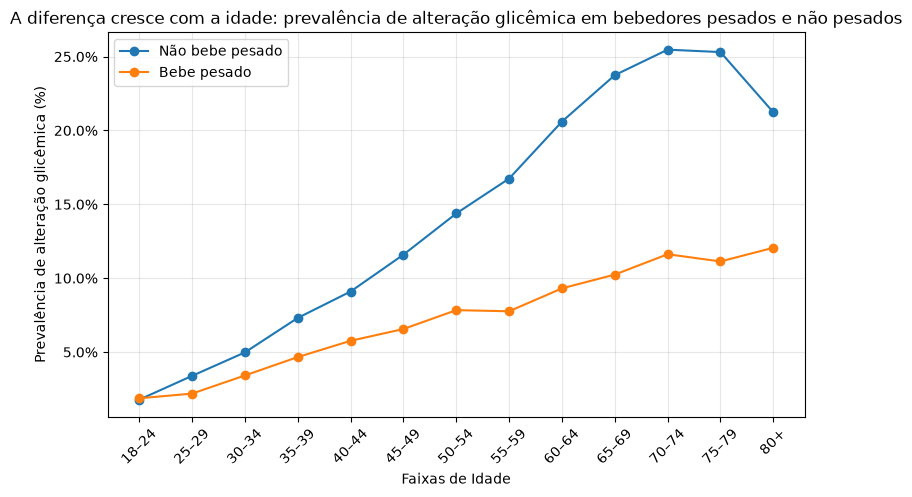

In [32]:
tab = expl.groupby(["_AGEG5YR", "_RFDRHV5"])["alvo"].mean().unstack()
tab.columns = ["Não bebe pesado", "Bebe pesado"]   # nomes legíveis na legenda
FAIXAS = ["18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54",
          "55–59", "60–64", "65–69", "70–74", "75–79", "80+"]   # códigos 1 a 13 do _AGEG5YR
ax = tab.plot(marker="o", figsize=(9, 5))
ax.set_xticks(range(1, 14))                          # um tick por código...
ax.set_xticklabels(FAIXAS, rotation=45)              # ...com o nome da faixa no lugar do código
ax.yaxis.set_major_formatter(PercentFormatter(1.0))  # 0.25 → 25% (1.0 = o valor que vale 100%)

ax.set_xlabel("Faixas de Idade")
ax.set_ylabel("Prevalência de alteração glicêmica (%)")
ax.set_title("A diferença cresce com a idade: prevalência de alteração glicêmica em bebedores pesados e não pesados")
ax.grid(alpha=0.3)                                   # grade leve: ajuda a ler os valores

plt.savefig(ROOT / "reports" / "figures" / "alcool_vs_idade.png", dpi=150, bbox_inches="tight")

## A idade está muito mais fortemente associada à alteração glicêmica (1,8% → 25%) do que o consumo pesado de álcool (diferença de até ~2× dentro da mesma faixa, atingindo só 5% da população). Hipótese a verificar com SHAP na Fase 6.

## Agora vamos partir para mais uma pergunta na análise exploratória: quem se exercita tem menos alteração glicemica?

### O efeito biológico: o sedentarismo aumenta o risco. Então o grupo "não se exercita" deve ter mais alteração glicêmica.
### A causalidade reversa: o diagnosticado passa a se exercitar, então migra para o grupo "se exercita", levando o diagnóstico junto. Isso aumenta a prevalência no grupo que se exercita.

### Quem se exercita tem menos alteração glicêmica, mas a diferença real deve ser maior do que a que vamos ver, porque parte dos exercitantes são diabéticos que mudaram de hábito.

In [33]:
coluna = "EXERANY2"
validos = [1, 2]
rotulos = ["Se exercita", "Não se exercita"]
tab = prevalencia_por_idade(df, coluna, validos, rotulos)

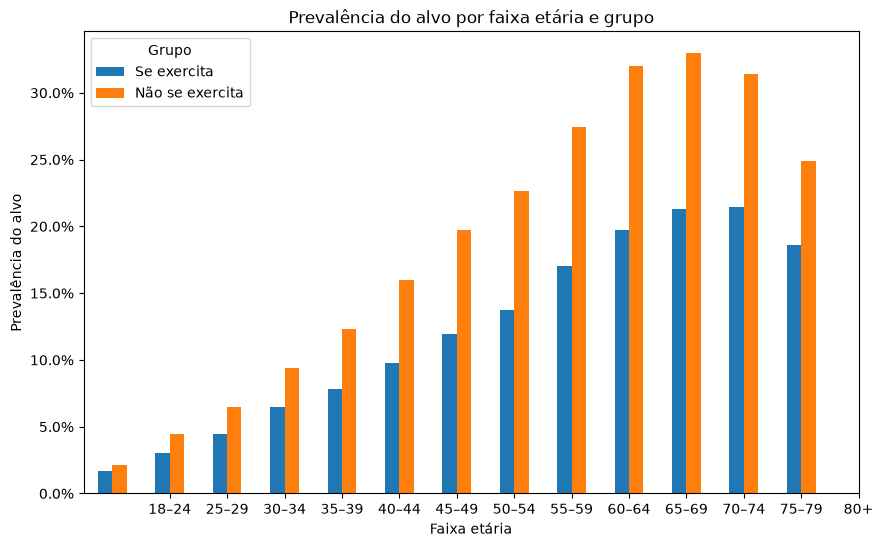

In [34]:
plot_prevalencia_por_idade(tab, rotulos)

### Vimos que no inicio da idade adulta o fato de não se exercitar não faz tanta diferença, mas já está associado com maior indice de alteração glicemica. Agora, na medida que a idade avança, mais aumenta a diferença entre quem se exercita e quem não se exercita.

In [ ]:
MANTER = [
    "_AGEG5YR",   # idade em faixas de 5 anos; preditor forte (D10)
    "SEX",        # 1-Male 2-Female
    "_BMI5CAT",         # Índice de Massa Corporal
    "_SMOKER3",   # 1 = todo dia, 2 = alguns dias, 3 = ex-fumante, 4 = nunca fumou
    "EXERANY2",   # 1 = sim, 2 = não. É invertido em relação ao _RFDRHV5.
    "_RFDRHV5",   # 1 = não, 2 = sim
    "_RFCHOL",    # 1 = não, 2 = sim, 9 = não sabe, vazio = nunca mediu
    "_RFHYPE5",    # 1 = não, 2 = sim, 9 = não sabe
    "GENHLTH"     # 1 = excelente, 2 = muito boa, 3 = boa, 4 = razoável, 5 = ruim, 7 = não sabe, 9 = recusa
    "DIFFWALK",   # 1 = sim, 2 = não, 7 = não sabe, 9 = recusa
]

### Fato interessante na escolha das colunas, selecionei inicialmente a coluna SMOKDAY2, no entanto, essa é uma pergunta de seguimento, ou seja só respondida se SMOKE100 for positiva. O que iria gerar muitos nulos e eliminar diversas linhas da base na limpeza dos dados nulos.

### Neste caso, optei por usar SMOKE100 que combina SMOKE100 e SMOKDAY2 numa variavel calculada.